<a href="https://colab.research.google.com/github/luiscalvi/CSC349/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Luis Calvillo

Task 1: Load the dataset into a Pandas DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns)

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

In [2]:
# Display first five rows
display(df.head())

# Display dataset structure
df.info()

# Display numerical statistics
display(df.describe())

# Display categorical statistics
display(df.describe(include="object"))


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


,ca,thal
count,303,303
unique,5,4
top,0.0,3.0
freq,176,166


Task 3: Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.

In [3]:
from sklearn.impute import SimpleImputer

# Count hidden missing values
print("Hidden Missing Values:")
print((df == "?").sum())

# Replace question marks with NaN
df = df.replace("?", np.nan)

# Convert columns to numerical format
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Count missing values
print("\nMissing Values by Column:")
print(df.isnull().sum())

# Define imputation strategies
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

print("\nImputation strategies created.")

Hidden Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Missing Values by Column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Imputation strategies created.


Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical columns
numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Identify categorical columns
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", numeric_imputer),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Separate features and target
X = df.drop("target", axis=1)

# Convert target into binary classes
y = (df["target"] > 0).astype(int)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Size:", X_train.shape)
print("Testing Size:", X_test.shape)

Training Size: (242, 13)
Testing Size: (61, 13)


Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

SVC Confusion Matrix:
[[28  5]
 [ 2 26]]


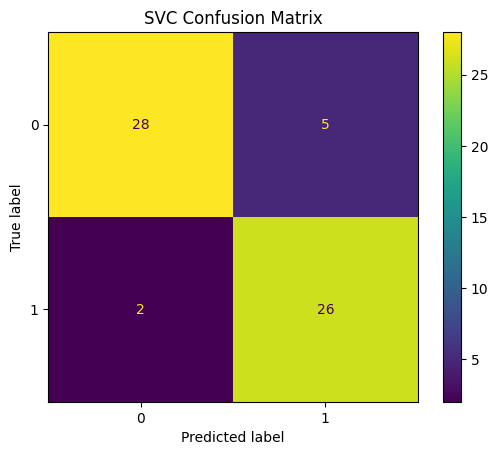

SVC Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

SVC ROC-AUC: 0.9642857142857143


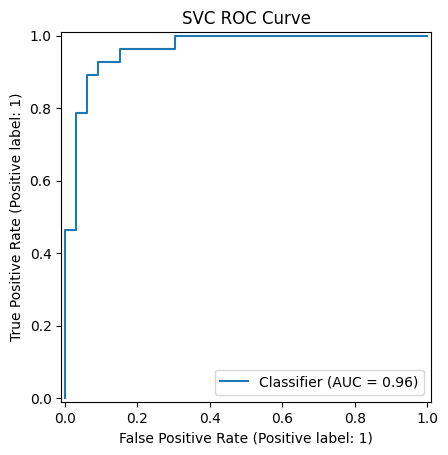

In [5]:
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)

# Create SVC pipeline
svc_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

# Train model
svc_pipeline.fit(X_train, y_train)

# Make predictions
svc_predictions = svc_pipeline.predict(X_test)
svc_probabilities = svc_pipeline.predict_proba(X_test)[:, 1]

# Confusion matrix
print("SVC Confusion Matrix:")
print(confusion_matrix(y_test, svc_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test, svc_predictions
)
plt.title("SVC Confusion Matrix")
plt.show()

# Classification report
print("SVC Classification Report:")
print(classification_report(y_test, svc_predictions))

# ROC-AUC score
svc_auc = roc_auc_score(y_test, svc_probabilities)
print("SVC ROC-AUC:", svc_auc)

# ROC curve
RocCurveDisplay.from_predictions(
    y_test, svc_probabilities
)
plt.title("SVC ROC Curve")
plt.show()

Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

Decision Tree Confusion Matrix:
[[22 11]
 [ 5 23]]


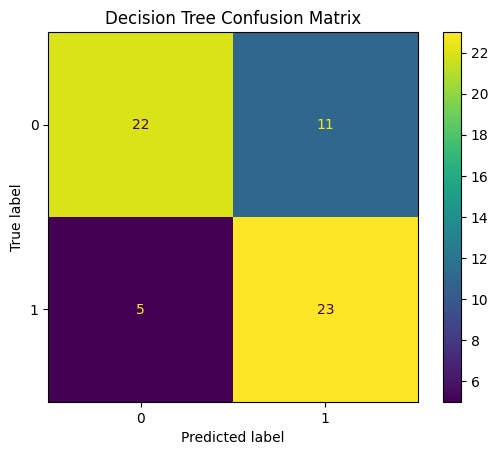

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61

Decision Tree ROC-AUC: 0.7440476190476191


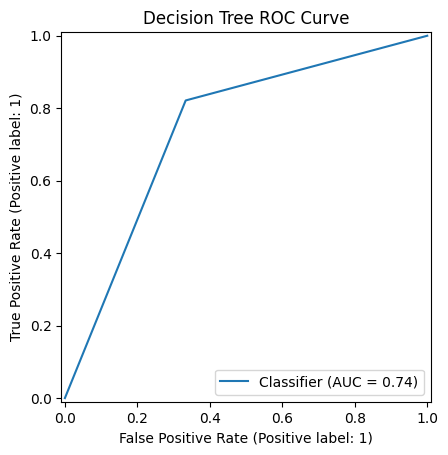


Model Comparison:
SVC ROC-AUC: 0.9642857142857143
Decision Tree ROC-AUC: 0.7440476190476191


In [6]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
tree_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Train model
tree_pipeline.fit(X_train, y_train)

# Make predictions
tree_predictions = tree_pipeline.predict(X_test)
tree_probabilities = tree_pipeline.predict_proba(X_test)[:, 1]

# Confusion matrix
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, tree_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test, tree_predictions
)
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Classification report
print("Decision Tree Classification Report:")
print(classification_report(y_test, tree_predictions))

# ROC-AUC score
tree_auc = roc_auc_score(y_test, tree_probabilities)
print("Decision Tree ROC-AUC:", tree_auc)

# ROC curve
RocCurveDisplay.from_predictions(
    y_test, tree_probabilities
)
plt.title("Decision Tree ROC Curve")
plt.show()

# Compare models
print("\nModel Comparison:")
print("SVC ROC-AUC:", svc_auc)
print("Decision Tree ROC-AUC:", tree_auc)

Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

In [7]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter options
param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1, 1]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

# Train and tune
grid_search.fit(X_train, y_train)

# Display results
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

# Evaluate the best model
best_svc = grid_search.best_estimator_

best_predictions = best_svc.predict(X_test)
best_probabilities = best_svc.predict_proba(X_test)[:, 1]

print("\nTuned SVC Classification Report:")
print(classification_report(y_test, best_predictions))

print("Tuned SVC Test ROC-AUC:")
print(roc_auc_score(y_test, best_probabilities))

Best Parameters:
{'classifier__C': 1, 'classifier__gamma': 0.01}

Best Cross-Validation ROC-AUC:
0.8882830535004448

Tuned SVC Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91        33
           1       0.87      0.93      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61

Tuned SVC Test ROC-AUC:
0.9675324675324675


Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

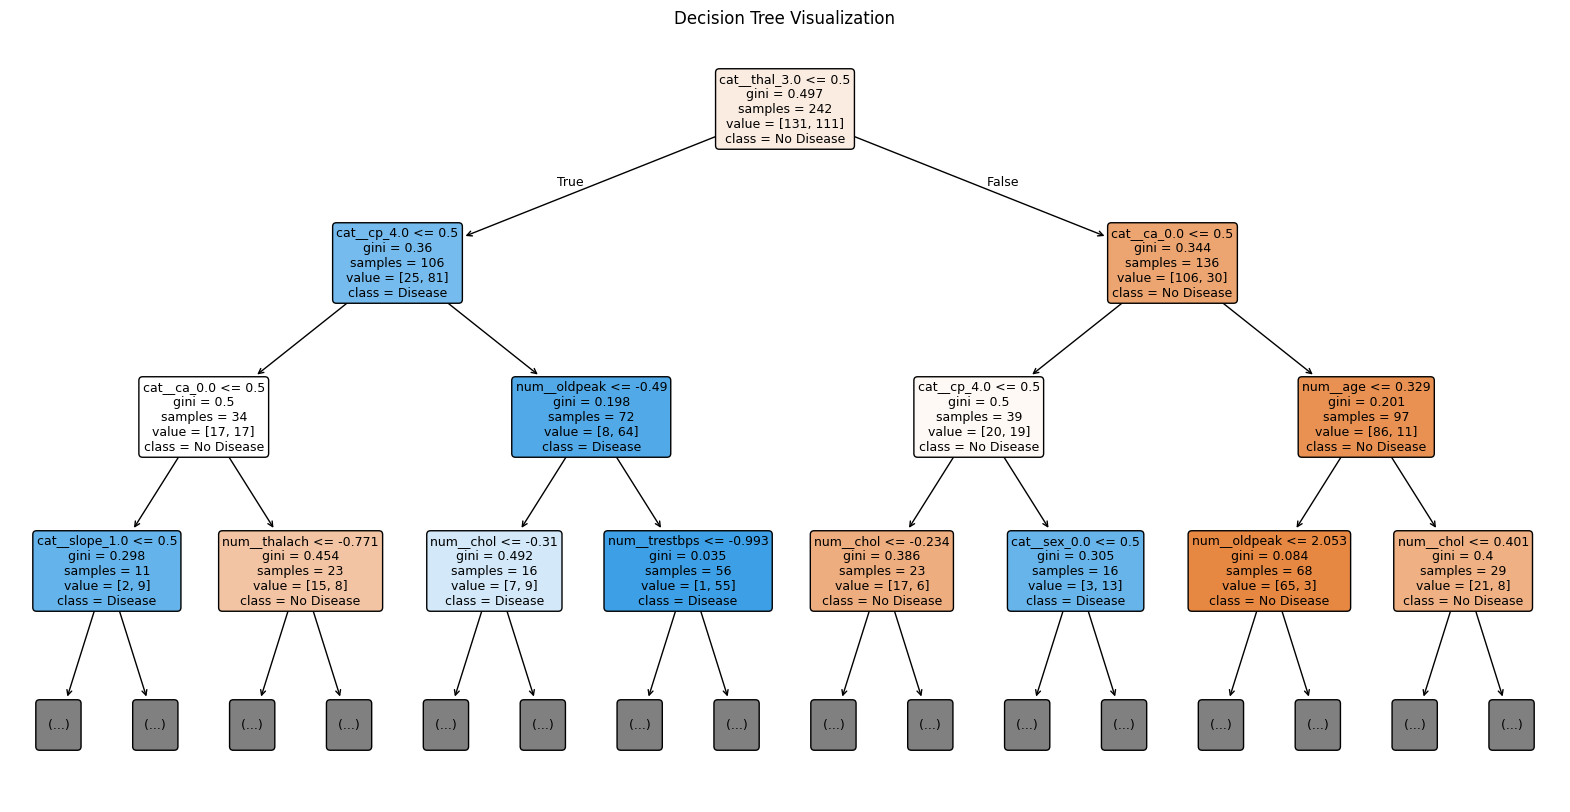

Feature Importances:
thal        0.292921
cp          0.144734
ca          0.111887
chol        0.110055
oldpeak     0.107935
age         0.096128
sex         0.033909
trestbps    0.027639
thalach     0.018673
fbs         0.016444
slope       0.016138
exang       0.015216
restecg     0.008321
dtype: float64


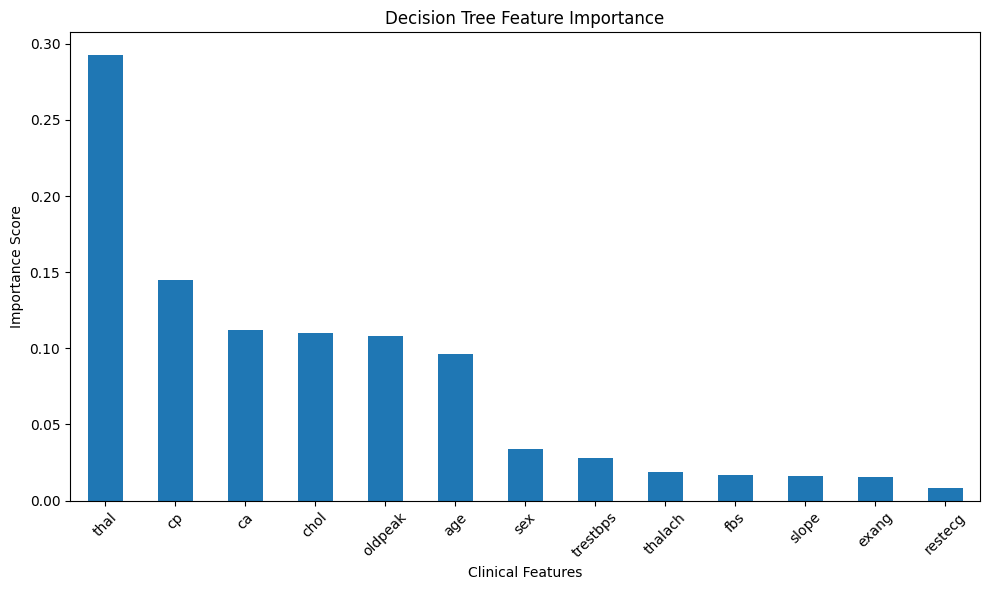

In [8]:
from sklearn.tree import plot_tree

# Extract trained Decision Tree
tree_model = tree_pipeline.named_steps["classifier"]

# Get transformed feature names
feature_names = (
    tree_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization")
plt.show()

# Calculate feature importances
importances = pd.Series(
    tree_model.feature_importances_,
    index=feature_names
)

# Combine encoded categories into original features
grouped_importances = {}

for col in numerical_features:
    grouped_importances[col] = importances.get(
        f"num__{col}", 0
    )

for col in categorical_features:
    mask = importances.index.str.startswith(
        f"cat__{col}_"
    )
    grouped_importances[col] = importances[mask].sum()

# Sort importance scores
feature_importance = pd.Series(
    grouped_importances
).sort_values(ascending=False)

print("Feature Importances:")
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

feature_importance.plot(kind="bar")

plt.title("Decision Tree Feature Importance")
plt.xlabel("Clinical Features")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()